# Nhiệm vụ 4: Học có giám sát – Pipeline Phân loại (Classification)

Dữ liệu: `cgv_eda_cleaned.csv`.

Các bước:
1. **Đặc trưng mục tiêu:** dự đoán nhãn phân loại rời rạc (mức nhu cầu của suất chiếu: Cao / Không cao)
2. **Thuật toán:** `LogisticRegression()` và `DecisionTreeClassifier()`
3. **Xử lý mất cân bằng:** kiểm tra phân bố nhãn, áp dụng `class_weight='balanced'` và lấy mẫu lại (oversampling)
4. **Đầu ra đánh giá:** Confusion Matrix heatmap và `classification_report` (Precision, Recall, Accuracy, F1-Score)

## 1. Đọc dữ liệu

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier
from sklearn.utils import resample
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report)

plt.rcParams["figure.dpi"] = 110
RANDOM_STATE = 42

df = pd.read_csv("cgv_eda_cleaned.csv", encoding="utf-8-sig")
print("Số dòng:", len(df), "| Số cột:", len(df.columns))
df.head(3)

Số dòng: 1172 | Số cột: 18


,MovieName,Cinema,ShowDate,Format,ShowTime,GeneratedText,TicketPrice,AvailableSeats,TotalSeats,MovieURL,Rating,Director,Actors,Genre,ReleaseDate,Duration,Language,DurationMinutes
0,AVENGERS: HỒI KẾT - PHIÊN BẢN ĐẶC BIỆT (CHIẾU ...,CGV Crescent Mall,2026-10-01,2D Phụ Đề Việt | Rạp Lamour,10:30,Tôi đã có cơ hội xem suất chiếu AVENGERS: HỒI ...,65000,72,100,https://www.cgv.vn/default/avengers-endgame-en...,T13,"Anthony Russo, Joe Russo","Robert Downey Jr., Chris Evans, Mark Ruffalo, ...","Hành Động, Khoa Học Viễn Tưởng, Phiêu Lưu",2026-09-25,183 phút,Tiếng Anh với phụ đề tiếng Việt,183.0
1,AVENGERS: HỒI KẾT - PHIÊN BẢN ĐẶC BIỆT (CHIẾU ...,CGV Crescent Mall,2026-10-01,2D Phụ Đề Việt | Rạp Lamour,16:00,"Hôm nay, tôi có cơ hội tham gia vào một trải n...",70000,65,100,https://www.cgv.vn/default/avengers-endgame-en...,T13,"Anthony Russo, Joe Russo","Robert Downey Jr., Chris Evans, Mark Ruffalo, ...","Hành Động, Khoa Học Viễn Tưởng, Phiêu Lưu",2026-09-25,183 phút,Tiếng Anh với phụ đề tiếng Việt,183.0
2,AVENGERS: HỒI KẾT - PHIÊN BẢN ĐẶC BIỆT (CHIẾU ...,CGV Crescent Mall,2026-10-01,2D Phụ Đề Việt | Rạp Lamour,21:30,Tôi đã có cơ hội xem suất chiếu AVENGERS: HỒI ...,75000,53,100,https://www.cgv.vn/default/avengers-endgame-en...,T13,"Anthony Russo, Joe Russo","Robert Downey Jr., Chris Evans, Mark Ruffalo, ...","Hành Động, Khoa Học Viễn Tưởng, Phiêu Lưu",2026-09-25,183 phút,Tiếng Anh với phụ đề tiếng Việt,183.0


## 2. Đặc trưng mục tiêu (Target Feature)

Dữ liệu lịch chiếu không có nhãn nhu cầu thực tế do CGV cung cấp. Vì vậy, nhóm xây dựng nhãn đại diện `DemandLevel` từ tỷ lệ lấp đầy ghế:

`OccupancyRate = (TotalSeats − AvailableSeats) / TotalSeats`

- **Cao**: `OccupancyRate` lớn hơn trung vị của dataset mới.
- **Không cao**: `OccupancyRate` nhỏ hơn hoặc bằng trung vị.

Ngưỡng được tính lại từ dataset mới trong quá trình chạy notebook (không cố định ở mức 20%). Đây là nhãn đại diện được suy ra từ dữ liệu ghế, không phải nhãn doanh thu hoặc nhu cầu khách hàng được xác nhận từ hệ thống CGV.

Bài toán phân loại nhị phân nhằm nhận diện các suất chiếu có tỷ lệ lấp đầy cao hơn mức trung vị của tập dữ liệu.

In [2]:
df["OccupancyRate"] = (df["TotalSeats"] - df["AvailableSeats"]) / df["TotalSeats"]

threshold = df["OccupancyRate"].median()
print(f"Ngưỡng (trung vị tỉ lệ lấp đầy): {threshold:.1%}")

df["DemandLevel"] = np.where(df["OccupancyRate"] > threshold, "Cao", "Không cao")
y = df["DemandLevel"]

print("\nSố lượng từng nhãn:")
print(y.value_counts())
print("\nTỉ lệ từng nhãn:")
print(y.value_counts(normalize=True).round(3))

Ngưỡng (trung vị tỉ lệ lấp đầy): 34.0%

Số lượng từng nhãn:
DemandLevel
Không cao    609
Cao          563
Name: count, dtype: int64

Tỉ lệ từng nhãn:
DemandLevel
Không cao    0.52
Cao          0.48
Name: proportion, dtype: float64


### 2.1. Kiểm tra tình trạng mất cân bằng nhãn

Sau khi cập nhật dataset, cần tính lại số lượng và tỷ lệ của hai nhãn. Không sử dụng lại tỷ lệ 28% / 72% của phiên bản dữ liệu trước.

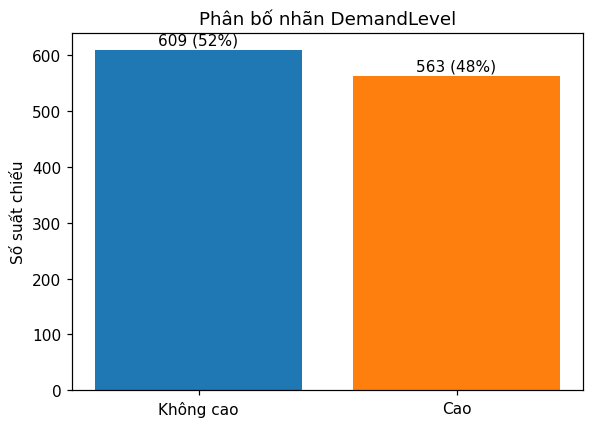

Tỉ lệ lớp đa số / lớp thiểu số: 1.08:1
=> Hai nhãn tương đối cân bằng; vẫn nên xem Precision, Recall và F1 của lớp Cao để đánh giá khả năng phát hiện suất chiếu có tỷ lệ lấp đầy cao.


In [3]:
counts = y.value_counts()
fig, ax = plt.subplots(figsize=(5.5, 4))
bars = ax.bar(counts.index, counts.values, color=["#1f77b4", "#ff7f0e"])
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 10, f"{v} ({v/len(y):.0%})", ha="center")
ax.set_title("Phân bố nhãn DemandLevel")
ax.set_ylabel("Số suất chiếu")
plt.tight_layout()
plt.show()

ratio = counts.max() / counts.min()
print(f"Tỉ lệ lớp đa số / lớp thiểu số: {ratio:.2f}:1")
print("=> Hai nhãn tương đối cân bằng; vẫn nên xem Precision, Recall và F1 của lớp Cao để đánh giá khả năng phát hiện suất chiếu có tỷ lệ lấp đầy cao.")

## 3. Chuẩn bị đặc trưng đầu vào (X)

- Số: `DurationMinutes`, `ShowHour`, `DaysSinceRelease`, `IsWeekend`, `IsPremiumRoom`, `TotalSeats`, `TicketPrice`
- Biến phân loại → số: one-hot `Cinema`, `Rating`, loại định dạng chiếu (`FormatTech`); multi-hot `Genre`

**Tránh rò rỉ dữ liệu:** loại `AvailableSeats` (và mọi cột suy ra từ nó) khỏi X vì nhãn được tính trực tiếp từ cột này.

In [4]:
feat = pd.DataFrame(index=df.index)

feat["DurationMinutes"] = pd.to_numeric(df["DurationMinutes"], errors="coerce")
t = pd.to_datetime(df["ShowTime"], format="%H:%M", errors="coerce")
feat["ShowHour"] = t.dt.hour + t.dt.minute / 60

show_date = pd.to_datetime(df["ShowDate"], format="%Y-%m-%d", errors="coerce")
release_date = pd.to_datetime(df["ReleaseDate"], format="%Y-%m-%d", errors="coerce")
feat["DaysSinceRelease"] = (show_date - release_date).dt.days
feat["IsWeekend"] = (show_date.dt.dayofweek >= 5).astype(int)

fmt = df["Format"].astype(str).str.replace(r"\s+", " ", regex=True).str.strip()
df["FormatTech"] = fmt.str.split(r" Phụ| Lồng", n=1, regex=True).str[0].str.strip()
feat["IsPremiumRoom"] = fmt.str.contains(r"\|", regex=True).astype(int)
feat["TotalSeats"] = pd.to_numeric(df["TotalSeats"], errors="coerce")
feat["TicketPrice"] = pd.to_numeric(df["TicketPrice"], errors="coerce")

cat_dummies = pd.get_dummies(df[["Cinema", "Rating", "FormatTech"]], dtype=int)
genre_dummies = df["Genre"].str.get_dummies(sep=", ").add_prefix("Genre_")

X = pd.concat([feat, cat_dummies, genre_dummies], axis=1)

print("Kích thước X:", X.shape)
print("Giá trị thiếu trong X:", int(X.isna().sum().sum()))
X.head(3)

Kích thước X: (1172, 31)
Giá trị thiếu trong X: 0


,DurationMinutes,ShowHour,DaysSinceRelease,IsWeekend,IsPremiumRoom,TotalSeats,TicketPrice,Cinema_CGV Crescent Mall,Cinema_CGV Hùng Vương Plaza,Cinema_CGV Thảo Điền Pearl,...,Genre_Gia đình,Genre_Hoạt Hình,Genre_Hài,Genre_Hành Động,Genre_Hồi hộp,Genre_Khoa Học Viễn Tưởng,Genre_Kinh Dị,Genre_Phiêu Lưu,Genre_Thần thoại,Genre_Tâm Lý
0,183.0,10.5,6,0,1,100,65000,1,0,0,...,0,0,0,1,0,1,0,1,0,0
1,183.0,16.0,6,0,1,100,70000,1,0,0,...,0,0,0,1,0,1,0,1,0,0
2,183.0,21.5,6,0,1,100,75000,1,0,0,...,0,0,0,1,0,1,0,1,0,0


## 4. Chia tập Train / Test (có phân tầng)

Dùng `stratify=y` để giữ nguyên tỉ lệ nhãn ở cả hai tập, điều quan trọng khi dữ liệu mất cân bằng.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Tỉ lệ 'Cao' - train:", round((y_train == "Cao").mean(), 3), "| test:", round((y_test == "Cao").mean(), 3))

Train: (937, 31) | Test: (235, 31)
Tỉ lệ 'Cao' - train: 0.48 | test: 0.481


## 5. Huấn luyện và so sánh: có và không xử lý mất cân bằng

Với mỗi thuật toán (`LogisticRegression`, `DecisionTreeClassifier`) thử 3 cách:
1. **Không xử lý** mất cân bằng
2. **`class_weight='balanced'`**: tăng trọng số lỗi cho lớp thiểu số
3. **Random oversampling**: nhân bản ngẫu nhiên mẫu lớp thiểu số trong tập train (chỉ trên train để không rò rỉ sang test)

Cây quyết định được giới hạn độ sâu (`max_depth=4`, `min_samples_leaf=20`) để tránh overfit; bước tinh chỉnh bằng `GridSearchCV` ở mục 7.

In [6]:
# Random oversampling trên tập train
train_df = X_train.copy()
train_df["__y__"] = y_train.values
major = train_df[train_df["__y__"] == "Không cao"]
minor = train_df[train_df["__y__"] == "Cao"]
minor_up = resample(minor, replace=True, n_samples=len(major), random_state=RANDOM_STATE)
train_os = pd.concat([major, minor_up]).sample(frac=1, random_state=RANDOM_STATE)
X_train_os = train_os.drop(columns="__y__")
y_train_os = train_os["__y__"]
print("Sau oversampling:", y_train_os.value_counts().to_dict())

Sau oversampling: {'Không cao': 487, 'Cao': 487}


In [7]:
def make_model(kind, balanced):
    cw = "balanced" if balanced else None
    if kind == "LogisticRegression":
        return make_pipeline(StandardScaler(),
                             LogisticRegression(class_weight=cw, max_iter=2000, random_state=RANDOM_STATE))
    return DecisionTreeClassifier(max_depth=4, min_samples_leaf=20,
                                  class_weight=cw, random_state=RANDOM_STATE)

experiments = {}   # (tên mô hình, cách xử lý) -> mô hình đã huấn luyện
for kind in ["LogisticRegression", "DecisionTreeClassifier"]:
    experiments[(kind, "Không xử lý")] = make_model(kind, False).fit(X_train, y_train)
    experiments[(kind, "class_weight='balanced'")] = make_model(kind, True).fit(X_train, y_train)
    experiments[(kind, "Random oversampling")] = make_model(kind, False).fit(X_train_os, y_train_os)

baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)

print("Đã huấn luyện", len(experiments), "mô hình + 1 mô hình cơ sở")

Đã huấn luyện 6 mô hình + 1 mô hình cơ sở


## 6. Đánh giá trên tập test

Lớp quan tâm (positive) là **'Cao'**.

In [8]:
POS = "Cao"

def metrics(model, Xa, ya):
    pred = model.predict(Xa)
    proba = model.predict_proba(Xa)[:, list(model.classes_).index(POS)]
    return {
        "Accuracy": accuracy_score(ya, pred),
        "Precision (Cao)": precision_score(ya, pred, pos_label=POS, zero_division=0),
        "Recall (Cao)": recall_score(ya, pred, pos_label=POS, zero_division=0),
        "F1 (Cao)": f1_score(ya, pred, pos_label=POS, zero_division=0),
        "F1 macro": f1_score(ya, pred, average="macro"),
        "ROC-AUC": roc_auc_score((ya == POS).astype(int), proba),
    }

rows = {"Cơ sở (luôn đoán lớp đa số)": metrics(baseline, X_test, y_test)}
for (kind, how), mdl in experiments.items():
    rows[f"{kind} | {how}"] = metrics(mdl, X_test, y_test)

results = pd.DataFrame(rows).T
pd.options.display.float_format = "{:.3f}".format
display(results)

,Accuracy,Precision (Cao),Recall (Cao),F1 (Cao),F1 macro,ROC-AUC
Cơ sở (luôn đoán lớp đa số),0.519,0.000,0.000,0.000,0.342,0.500
LogisticRegression | Không xử lý,0.770,0.744,0.796,0.769,0.770,0.840
LogisticRegression | class_weight='balanced',0.770,0.740,0.805,0.771,0.770,0.840
LogisticRegression | Random oversampling,0.753,0.724,0.788,0.754,0.753,0.838
DecisionTreeClassifier | Không xử lý,0.813,0.780,0.850,0.814,0.813,0.866
DecisionTreeClassifier | class_weight='balanced',0.813,0.780,0.850,0.814,0.813,0.866
DecisionTreeClassifier | Random oversampling,0.779,0.752,0.805,0.778,0.779,0.855


**Cách đọc bảng:**
- Mô hình cơ sở luôn đoán lớp đa số có Accuracy bằng tỷ lệ lớp đa số nhưng Recall (Cao) = 0, nên không phát hiện được suất chiếu thuộc nhóm Cao.
- So sánh cả Precision, Recall, F1 của lớp `Cao`, F1 macro và ROC-AUC; không chỉ dựa vào Accuracy.
- Với dataset mới, hai lớp gần cân bằng hơn nên Accuracy có ý nghĩa tham khảo tốt hơn trước, nhưng vẫn cần ưu tiên các chỉ số của lớp `Cao` nếu mục tiêu là phát hiện suất chiếu có tỷ lệ lấp đầy cao.
- Xử lý mất cân bằng không mặc nhiên làm mọi chỉ số tăng; cần so sánh kết quả trên cùng tập test.

## 7. Tinh chỉnh cây quyết định (`GridSearchCV`)

Tìm `max_depth` và `min_samples_leaf` tốt nhất bằng kiểm tra chéo 5-fold phân tầng trên tập train, tối ưu **F1 macro**, kết hợp `class_weight='balanced'`.

In [9]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

grid = GridSearchCV(
    DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE),
    param_grid={"max_depth": [2, 3, 4, 5, 6, 8], "min_samples_leaf": [5, 10, 20, 40]},
    scoring="f1_macro", cv=cv,
).fit(X_train, y_train)

tree_tuned = grid.best_estimator_
print("Tham số tốt nhất:", grid.best_params_)
print(f"F1 macro (CV, train): {grid.best_score_:.3f}")

logit_bal = experiments[("LogisticRegression", "class_weight='balanced'")]

final_models = {
    "LogisticRegression (balanced)": logit_bal,
    "DecisionTree (tinh chỉnh, balanced)": tree_tuned,
}
final_results = pd.DataFrame({n: metrics(mdl, X_test, y_test) for n, mdl in final_models.items()}).T
display(final_results)

# Kiểm tra ổn định bằng cross-validation trên toàn bộ dữ liệu
for n, mdl in final_models.items():
    s = cross_val_score(mdl, X, y, cv=cv, scoring="f1_macro")
    print(f"{n}: F1 macro CV = {s.mean():.3f} ± {s.std():.3f}")
dummy_cv = cross_val_score(DummyClassifier(strategy="most_frequent"), X, y, cv=cv, scoring="f1_macro")
print(f"Cơ sở (lớp đa số): F1 macro CV = {dummy_cv.mean():.3f}")

Tham số tốt nhất: {'max_depth': 6, 'min_samples_leaf': 20}
F1 macro (CV, train): 0.806


,Accuracy,Precision (Cao),Recall (Cao),F1 (Cao),F1 macro,ROC-AUC
LogisticRegression (balanced),0.770,0.740,0.805,0.771,0.770,0.840
"DecisionTree (tinh chỉnh, balanced)",0.826,0.805,0.841,0.823,0.825,0.891


LogisticRegression (balanced): F1 macro CV = 0.796 ± 0.033
DecisionTree (tinh chỉnh, balanced): F1 macro CV = 0.814 ± 0.012
Cơ sở (lớp đa số): F1 macro CV = 0.342


## 8. Ma trận nhầm lẫn (Confusion Matrix heatmap)

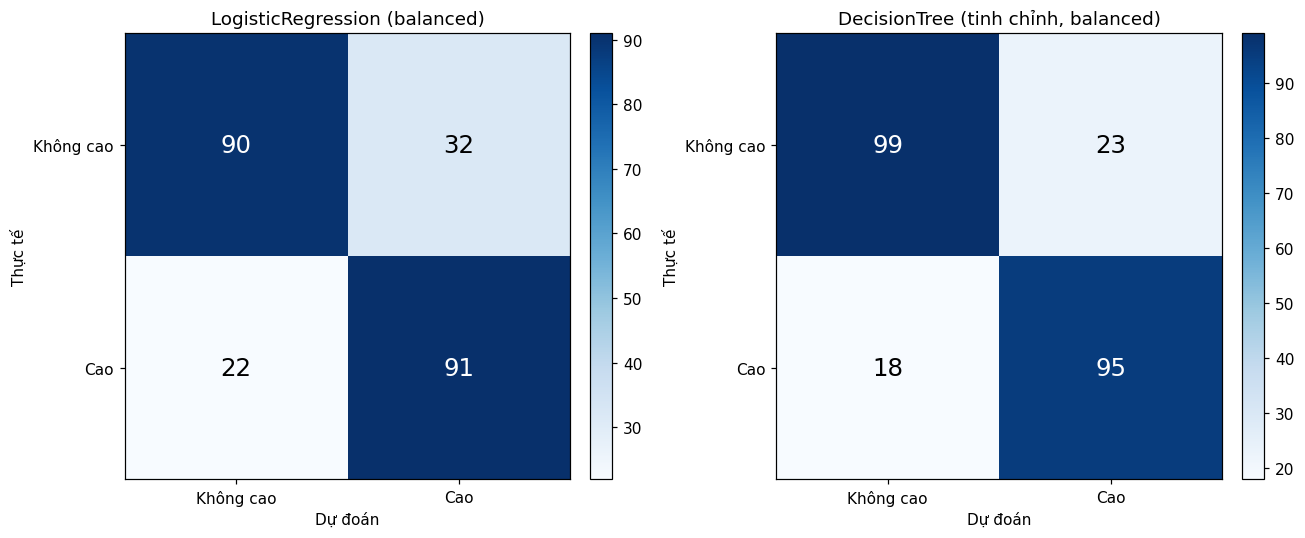

In [10]:
labels = ["Không cao", "Cao"]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, mdl) in zip(axes, final_models.items()):
    pred = mdl.predict(X_test)
    cm = confusion_matrix(y_test, pred, labels=labels)
    im = ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(2)); ax.set_xticklabels(labels)
    ax.set_yticks(range(2)); ax.set_yticklabels(labels)
    ax.set_xlabel("Dự đoán")
    ax.set_ylabel("Thực tế")
    ax.set_title(name)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=16,
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

## 9. Báo cáo phân loại chi tiết (`classification_report`)

In [11]:
for name, mdl in final_models.items():
    print("=" * 60)
    print(name)
    print("=" * 60)
    print(classification_report(y_test, mdl.predict(X_test), digits=3))

LogisticRegression (balanced)
              precision    recall  f1-score   support

         Cao      0.740     0.805     0.771       113
   Không cao      0.804     0.738     0.769       122

    accuracy                          0.770       235
   macro avg      0.772     0.772     0.770       235
weighted avg      0.773     0.770     0.770       235

DecisionTree (tinh chỉnh, balanced)
              precision    recall  f1-score   support

         Cao      0.805     0.841     0.823       113
   Không cao      0.846     0.811     0.828       122

    accuracy                          0.826       235
   macro avg      0.826     0.826     0.825       235
weighted avg      0.826     0.826     0.826       235



## 10. Đặc trưng nào ảnh hưởng nhiều nhất?

Sử dụng `feature_importances_` của Decision Tree và hệ số của Logistic Regression để xem các đặc trưng đóng góp như thế nào vào dự đoán. Feature importance thể hiện mức độ mô hình sử dụng đặc trưng để phân chia dữ liệu, không đồng nghĩa với quan hệ nhân quả.

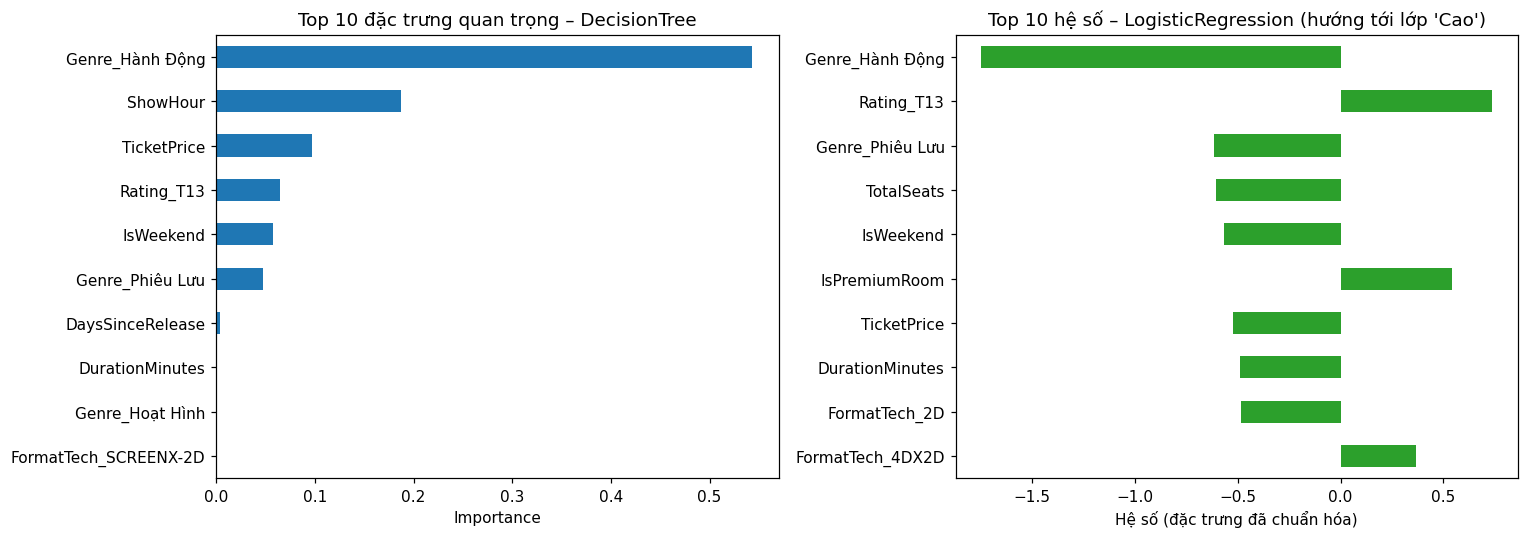

In [12]:
importances = pd.Series(tree_tuned.feature_importances_, index=X.columns).sort_values(ascending=False)
coef = pd.Series(logit_bal.named_steps["logisticregression"].coef_[0], index=X.columns)
top_coef = coef.reindex(coef.abs().sort_values(ascending=False).index).head(10)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
importances.head(10)[::-1].plot(kind="barh", ax=axes[0], color="#1f77b4")
axes[0].set_title("Top 10 đặc trưng quan trọng – DecisionTree")
axes[0].set_xlabel("Importance")

top_coef[::-1].plot(kind="barh", ax=axes[1], color="#2ca02c")
axes[1].set_title("Top 10 hệ số – LogisticRegression (hướng tới lớp 'Cao')")
axes[1].set_xlabel("Hệ số (đặc trưng đã chuẩn hóa)")
plt.tight_layout()
plt.show()

## 11. Kết luận

- **Biến mục tiêu:** `DemandLevel` (Cao / Không cao), được xây dựng từ `OccupancyRate = (TotalSeats - AvailableSeats) / TotalSeats`. Với dataset mới, trung vị OccupancyRate là **34%**. Có **563 suất Cao (48,0%)** và **609 suất Không cao (52,0%)**, nên hai lớp tương đối cân bằng (tỷ lệ lớp đa số/lớp thiểu số khoảng 1,08:1).
- **Chuẩn bị dữ liệu:** sử dụng 31 đặc trưng đầu vào, gồm thời lượng, giờ chiếu, số ngày từ ngày phát hành, cuối tuần, loại phòng, tổng số ghế, giá vé, rạp, phân loại phim và thể loại. Loại `AvailableSeats` khỏi X vì biến này tham gia trực tiếp vào công thức tạo nhãn.
- **So sánh mô hình:** Decision Tree tinh chỉnh (`max_depth=6`, `min_samples_leaf=20`, `class_weight='balanced'`) đạt Accuracy **82,6%**, F1 macro **0,825**, F1 lớp Cao **0,823** và ROC-AUC **0,891** trên tập test. Logistic Regression balanced đạt Accuracy **77,0%**, F1 macro **0,770**, F1 lớp Cao **0,771** và ROC-AUC **0,840**.
- **Khả năng phát hiện lớp Cao:** Decision Tree đạt Precision **80,5%** và Recall **84,1%**. Điều này có nghĩa là trong các mẫu được dự đoán Cao, khoảng 80,5% là Cao; đồng thời mô hình phát hiện được khoảng 84,1% số mẫu Cao thực tế trong tập test. Kết quả này cân bằng hơn so với phiên bản dataset trước.
- **Kiểm tra chéo:** F1 macro trung bình 5-fold của Decision Tree đạt **0,814 ± 0,012**, cao hơn Logistic Regression **0,796 ± 0,033** và mô hình cơ sở **0,342**. Độ lệch chuẩn nhỏ của Decision Tree cho thấy kết quả giữa các fold tương đối ổn định trong phép chia hiện tại. Mô hình cơ sở có F1 macro CV khoảng 0,342.
- **Đặc trưng quan trọng:** theo Decision Tree, `Genre_Hành Động` có importance khoảng **0,543**, `ShowHour` khoảng **0,187**, `TicketPrice` khoảng **0,097**, tiếp theo là `Rating_T13`, `IsWeekend` và `Genre_Phiêu Lưu`. Đây là mức đóng góp trong cây đã huấn luyện, không chứng minh quan hệ nhân quả.
